In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("HR_Employee_Attrition.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1500, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,60,No,Travel_Rarely,927,Sales,1,4,Marketing,1,1001,...,3,80,0,17,4,3,17.0,1,12,3
1,50,No,Travel_Rarely,914,Research & Development,6,4,Other,1,1002,...,4,80,0,13,4,3,13.0,4,11,11
2,37,No,Travel_Frequently,1118,Sales,17,3,Medical,1,1003,...,4,80,2,25,6,2,25.0,15,11,16
3,31,No,Travel_Rarely,535,Sales,22,2,Life Sciences,1,1004,...,1,80,3,22,0,1,11.0,3,10,11
4,55,No,Travel_Rarely,1176,Research & Development,2,2,Other,1,1005,...,3,80,3,27,3,1,27.0,10,2,12


In [2]:
# Check dataset structure and data quality
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Employees:", df["EmployeeNumber"].nunique())

Dataset Shape: (1500, 35)

Data Types:
Age                           int64
Attrition                    object
BusinessTravel               object
DailyRate                     int64
Department                   object
DistanceFromHome              int64
Education                     int64
EducationField               object
EmployeeCount                 int64
EmployeeNumber                int64
EnvironmentSatisfaction       int64
Gender                       object
HourlyRate                    int64
JobInvolvement                int64
JobLevel                      int64
JobRole                      object
JobSatisfaction             float64
MaritalStatus                object
MonthlyIncome               float64
MonthlyRate                   int64
NumCompaniesWorked            int64
Over18                       object
OverTime                     object
PercentSalaryHike             int64
PerformanceRating             int64
RelationshipSatisfaction      int64
StandardHours            

In [3]:
# Calculate key HR workforce metrics
total_employees = df["EmployeeNumber"].nunique()
attrition_count = (df["Attrition"] == "Yes").sum()
active_employees = (df["Attrition"] == "No").sum()

attrition_rate = (attrition_count / len(df)) * 100

print("Total Employees:", total_employees)
print("Active Employees:", active_employees)
print("Employees Left:", attrition_count)
print("Attrition Rate:", round(attrition_rate, 2), "%")

Total Employees: 1500
Active Employees: 1291
Employees Left: 209
Attrition Rate: 13.93 %


In [4]:
# Check dataset structure
print("Dataset Shape:", df.shape)

# Check column data types
print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

# Check missing values
print("\nMissing Values:")
missing = df.isnull().sum()
display(missing[missing > 0].to_frame("Missing Count"))

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Check unique employee IDs
print("Unique Employee IDs:", df["EmployeeNumber"].nunique())

Dataset Shape: (1500, 35)

Data Types:


,Data Type
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64



Missing Values:


,Missing Count
BusinessTravel,8
JobSatisfaction,8
MonthlyIncome,8
YearsAtCompany,8



Duplicate Rows: 0
Unique Employee IDs: 1500


In [5]:
# Identify data quality issues
quality_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique(),
    "Data Type": df.dtypes.astype(str)
})

print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())

display(quality_report[quality_report["Missing Values"] > 0])

missing_report = df.isnull().sum()
print(missing_report[missing_report > 0])

Duplicate Rows: 0
Duplicate Employee IDs: 0


,Missing Values,Unique Values,Data Type
BusinessTravel,8,3,object
JobSatisfaction,8,4,float64
MonthlyIncome,8,1354,float64
YearsAtCompany,8,41,float64


BusinessTravel     8
JobSatisfaction    8
MonthlyIncome      8
YearsAtCompany     8
dtype: int64


In [6]:
# Handle missing values using appropriate methods

df["MonthlyIncome"] = df["MonthlyIncome"].fillna(
    df["MonthlyIncome"].median()
)

df["JobSatisfaction"] = df["JobSatisfaction"].fillna(
    df["JobSatisfaction"].median()
)

df["YearsAtCompany"] = df["YearsAtCompany"].fillna(
    df["YearsAtCompany"].median()
)

df["BusinessTravel"] = df["BusinessTravel"].fillna(
    df["BusinessTravel"].mode()[0]
)

print("Remaining Missing Values:", df.isnull().sum().sum())

Remaining Missing Values: 0


In [7]:
# Validate cleaned data
print("Remaining Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())

# Save cleaned dataset
df.to_csv("HR_Employee_Attrition_Cleaned.csv", index=False)

Remaining Missing Values: 0
Duplicate Rows: 0
Duplicate Employee IDs: 0


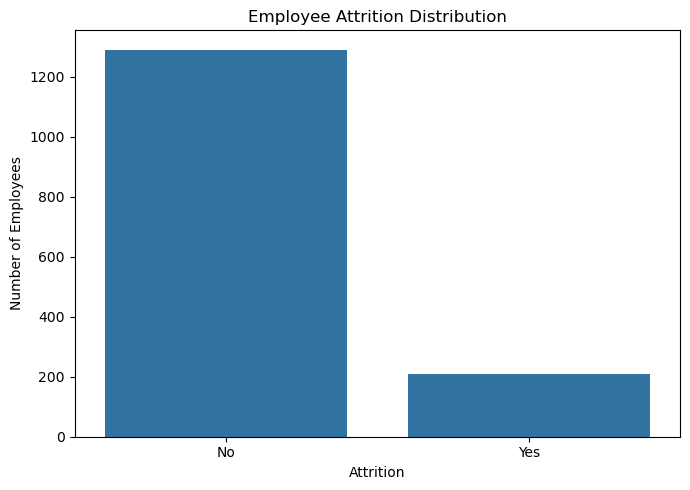

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize employee attrition distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

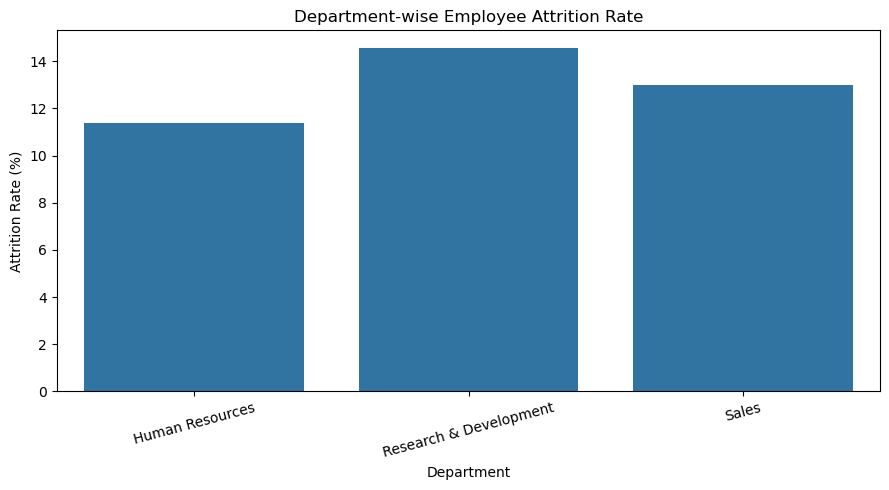

In [9]:
# Calculate attrition rate by department
dept_attrition = (
    df.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Attrition Rate")
)

# Visualize department-wise attrition rate
plt.figure(figsize=(9, 5))

sns.barplot(
    data=dept_attrition,
    x="Department",
    y="Attrition Rate"
)

plt.title("Department-wise Employee Attrition Rate")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

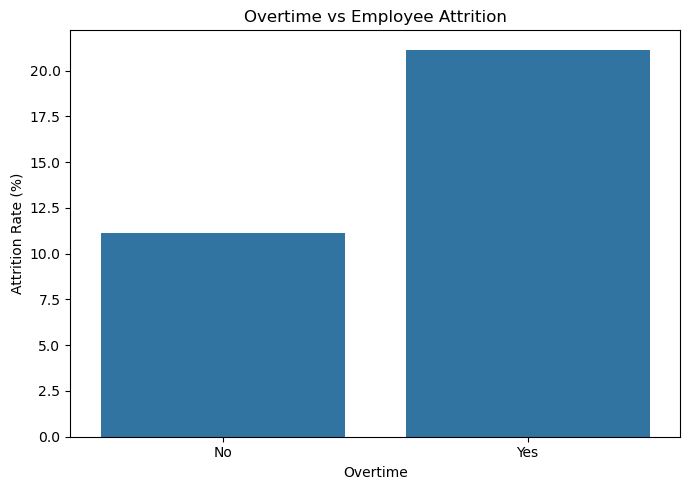

In [10]:
# Calculate attrition rate by overtime status
overtime_attrition = (
    df.groupby("OverTime")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Attrition Rate")
)

# Visualize overtime vs attrition
plt.figure(figsize=(7, 5))

sns.barplot(
    data=overtime_attrition,
    x="OverTime",
    y="Attrition Rate"
)

plt.title("Overtime vs Employee Attrition")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

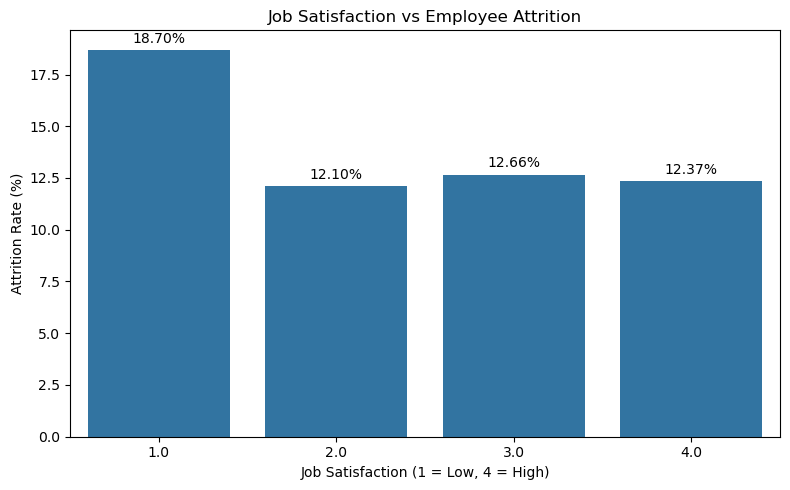

In [11]:
# Calculate attrition rate by job satisfaction
satisfaction_attrition = (
    df.groupby("JobSatisfaction")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Attrition Rate")
)

# Visualize satisfaction vs attrition
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=satisfaction_attrition,
    x="JobSatisfaction",
    y="Attrition Rate"
)

# Display values above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Job Satisfaction vs Employee Attrition")
plt.xlabel("Job Satisfaction (1 = Low, 4 = High)")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

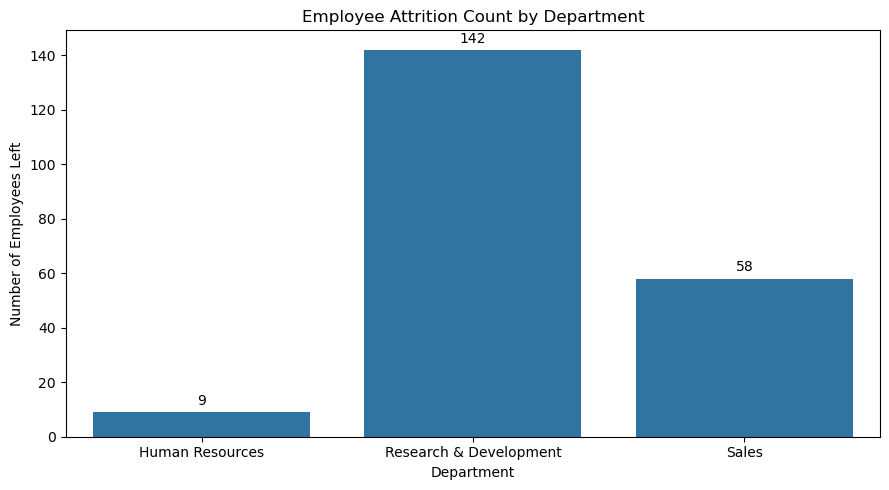

In [12]:
# Count employees who left by department
attrition_count = (
    df[df["Attrition"] == "Yes"]
    .groupby("Department")
    .size()
    .reset_index(name="Employees Left")
)

# Visualize attrition count by department
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=attrition_count,
    x="Department",
    y="Employees Left"
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.title("Employee Attrition Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees Left")
plt.tight_layout()
plt.show()

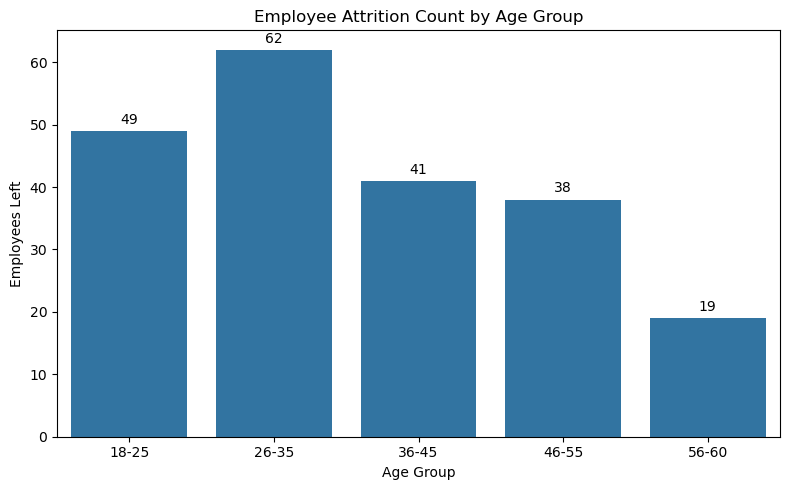

In [13]:
# Group employees by age
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-60"]
)

# Count employees who left in each age group
age_attrition = (
    df[df["Attrition"] == "Yes"]
    .groupby("AgeGroup", observed=False)
    .size()
    .reset_index(name="Employees Left")
)

# Plot attrition count by age group
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=age_attrition,
    x="AgeGroup",
    y="Employees Left"
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.title("Employee Attrition Count by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Employees Left")
plt.tight_layout()
plt.show()

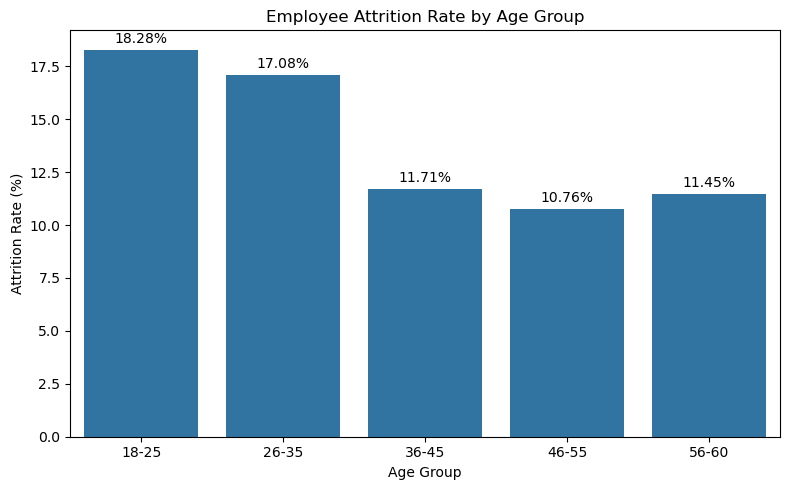

In [14]:
# Calculate attrition rate for each age group
age_attrition_rate = (
    df.groupby("AgeGroup", observed=False)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Attrition Rate")
)

# Create the bar chart
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=age_attrition_rate,
    x="AgeGroup",
    y="Attrition Rate"
)

# Display percentage labels above the bars
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

# Add chart title and axis labels
plt.title("Employee Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

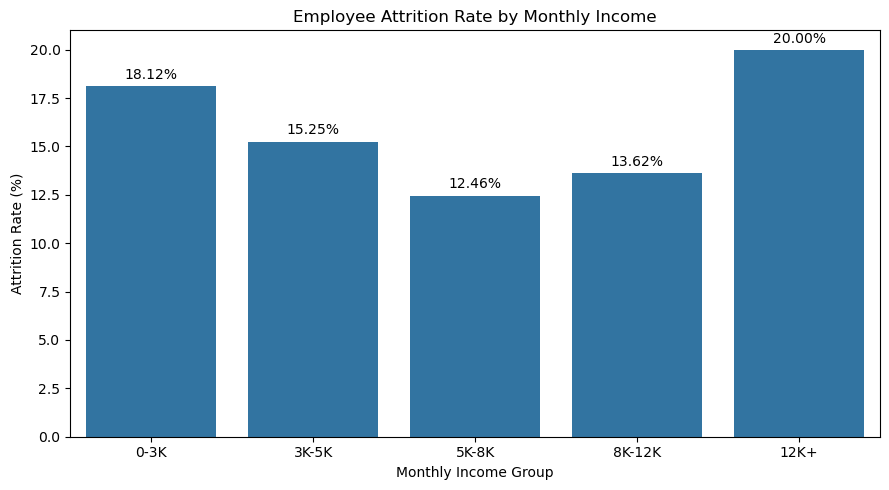

In [15]:
# Create salary groups for analysis
df["SalaryGroup"] = pd.cut(
    df["MonthlyIncome"],
    bins=[0, 3000, 5000, 8000, 12000, float("inf")],
    labels=["0-3K", "3K-5K", "5K-8K", "8K-12K", "12K+"]
)

# Calculate attrition rate for each salary group
salary_attrition_rate = (
    df.groupby("SalaryGroup", observed=False)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Attrition Rate")
)

# Create the bar chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=salary_attrition_rate,
    x="SalaryGroup",
    y="Attrition Rate"
)

# Display percentage labels above the bars
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

# Add chart title and axis labels
plt.title("Employee Attrition Rate by Monthly Income")
plt.xlabel("Monthly Income Group")
plt.ylabel("Attrition Rate (%)")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

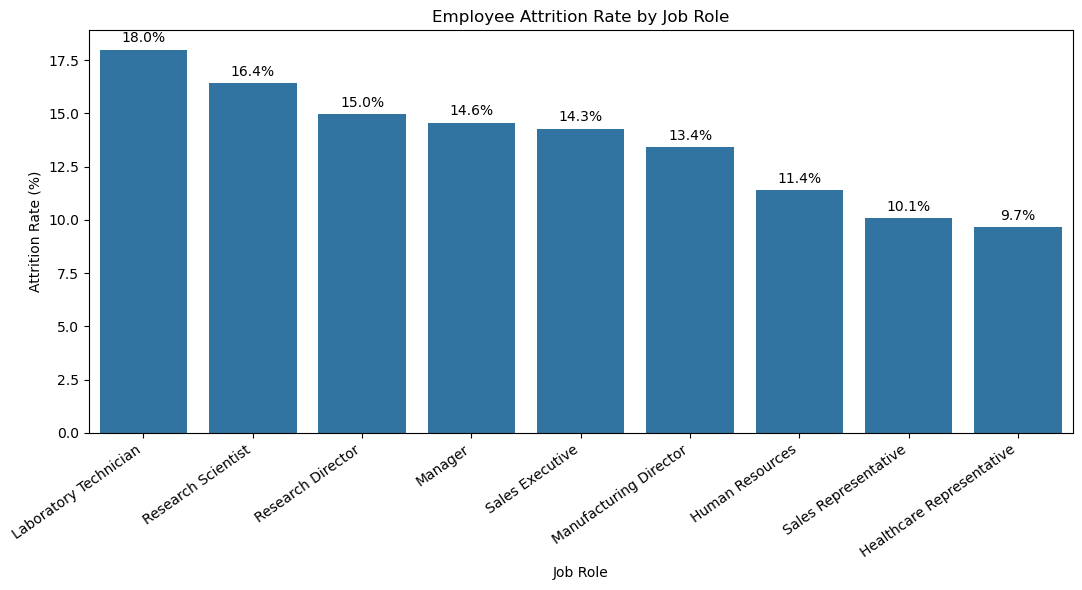

In [16]:
# Calculate attrition rate for each job role
role_attrition_rate = (
    df.groupby("JobRole")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Attrition Rate")
    .sort_values("Attrition Rate", ascending=False)
)

# Create the bar chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=role_attrition_rate,
    x="JobRole",
    y="Attrition Rate"
)

# Display percentage labels above the bars
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

# Add chart title and axis labels
plt.title("Employee Attrition Rate by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=35, ha="right")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

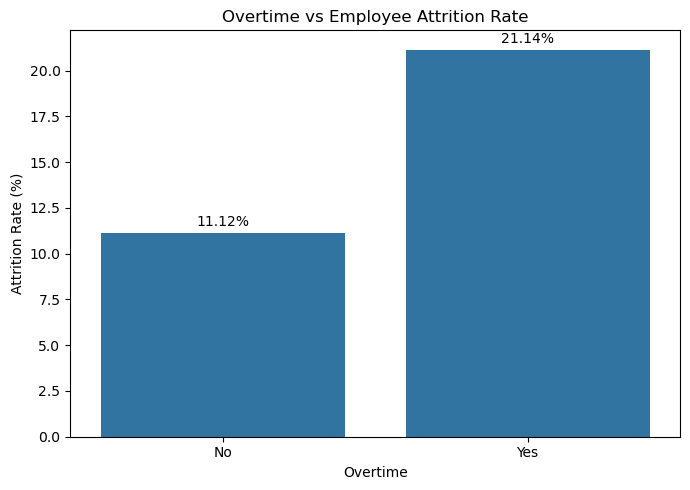

In [17]:
# Calculate attrition rate for each overtime group
overtime_attrition_rate = (
    df.groupby("OverTime")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Attrition Rate")
)

# Create the bar chart
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=overtime_attrition_rate,
    x="OverTime",
    y="Attrition Rate"
)

# Display percentage labels above the bars
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

# Add chart title and axis labels
plt.title("Overtime vs Employee Attrition Rate")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

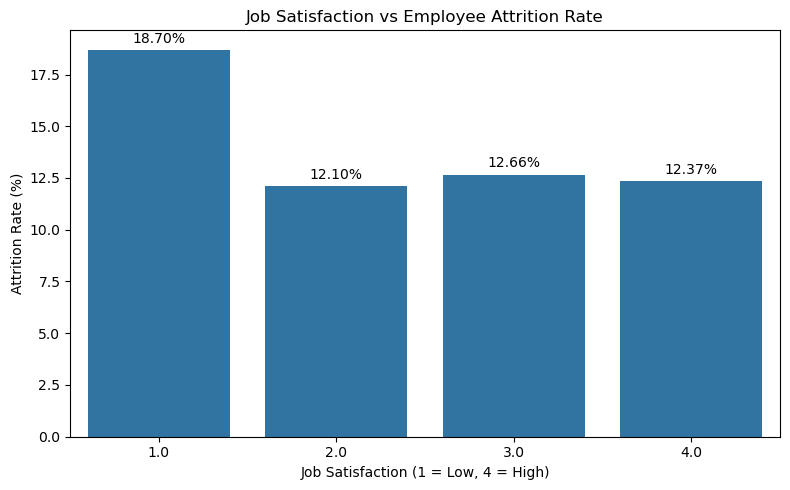

In [18]:
# Calculate attrition rate for each job satisfaction level
satisfaction_attrition_rate = (
    df.groupby("JobSatisfaction")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Attrition Rate")
)

# Create the bar chart
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=satisfaction_attrition_rate,
    x="JobSatisfaction",
    y="Attrition Rate"
)

# Display percentage labels above the bars
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

# Add chart title and axis labels
plt.title("Job Satisfaction vs Employee Attrition Rate")
plt.xlabel("Job Satisfaction (1 = Low, 4 = High)")
plt.ylabel("Attrition Rate (%)")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

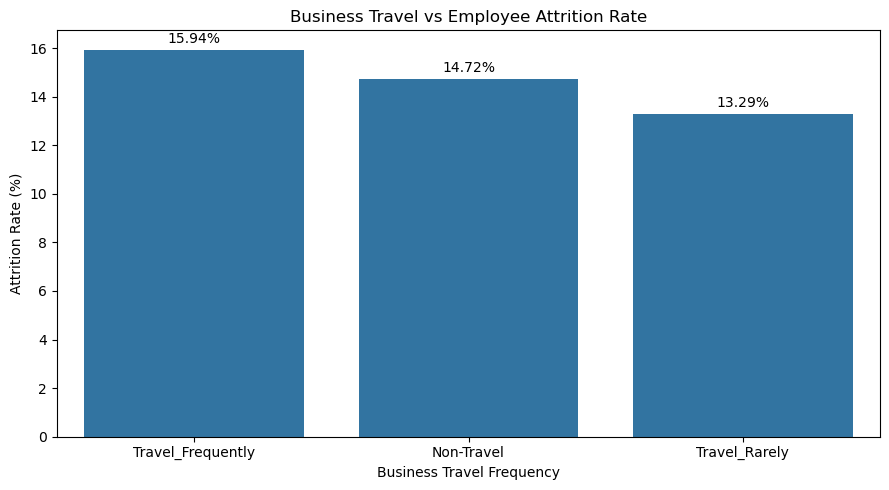

In [19]:
# Calculate attrition rate for each business travel group
travel_attrition_rate = (
    df.groupby("BusinessTravel")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Attrition Rate")
    .sort_values("Attrition Rate", ascending=False)
)

# Create the bar chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=travel_attrition_rate,
    x="BusinessTravel",
    y="Attrition Rate"
)

# Display percentage labels above the bars
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

# Add chart title and axis labels
plt.title("Business Travel vs Employee Attrition Rate")
plt.xlabel("Business Travel Frequency")
plt.ylabel("Attrition Rate (%)")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

In [20]:
# Calculate key workforce and attrition metrics
total_employees = len(df)
employees_left = (df["Attrition"] == "Yes").sum()
attrition_rate = (employees_left / total_employees) * 100

# Display the summary
print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print(f"Attrition Rate: {attrition_rate:.2f}%")

Total Employees: 1500
Employees Left: 209
Attrition Rate: 13.93%


In [21]:
# Summarize employee count and attrition by department
department_summary = (
    df.groupby("Department")
    .agg(
        Total_Employees=("EmployeeNumber", "count"),
        Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

# Calculate department-wise attrition rate
department_summary["Attrition_Rate_%"] = (
    department_summary["Employees_Left"]
    / department_summary["Total_Employees"]
    * 100
).round(2)

# Display the summary
department_summary

,Department,Total_Employees,Employees_Left,Attrition_Rate_%
0,Human Resources,79,9,11.39
1,Research & Development,974,142,14.58
2,Sales,447,58,12.98


In [22]:
# Define the categories to compare with attrition
analysis_groups = {
    "Department": "Department",
    "Overtime": "OverTime",
    "Job Satisfaction": "JobSatisfaction",
    "Business Travel": "BusinessTravel"
}

# Calculate attrition rate for each category
summary_list = []

for factor, column in analysis_groups.items():
    grouped = (
        df.groupby(column, dropna=False)["Attrition"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Attrition_Rate_%")
    )

    # Store category name and attrition rate
    for _, row in grouped.iterrows():
        summary_list.append({
            "Factor": factor,
            "Category": row[column],
            "Attrition_Rate_%": round(row["Attrition_Rate_%"], 2)
        })

# Combine all results into one summary table
attrition_factors_summary = pd.DataFrame(summary_list)

# Display the summary from highest to lowest attrition rate
attrition_factors_summary.sort_values(
    "Attrition_Rate_%",
    ascending=False
)

,Factor,Category,Attrition_Rate_%
4,Overtime,Yes,21.14
5,Job Satisfaction,1.0,18.70
10,Business Travel,Travel_Frequently,15.94
9,Business Travel,Non-Travel,14.72
1,Department,Research & Development,14.58
11,Business Travel,Travel_Rarely,13.29
2,Department,Sales,12.98
7,Job Satisfaction,3.0,12.66
8,Job Satisfaction,4.0,12.37
6,Job Satisfaction,2.0,12.10


In [ ]:
# Select the columns required for SQL analysis
sql_columns = [
    "EmployeeNumber", "Age", "Attrition", "BusinessTravel",
    "Department", "DistanceFromHome", "Education", "EducationField",
    "Gender", "JobLevel", "JobRole", "JobSatisfaction",
    "MaritalStatus", "MonthlyIncome", "OverTime", "PercentSalaryHike",
    "PerformanceRating", "TotalWorkingYears", "TrainingTimesLastYear",
    "WorkLifeBalance", "YearsAtCompany", "YearsInCurrentRole",
    "YearsSinceLastPromotion", "YearsWithCurrManager"
]

# Create a CSV containing only the selected columns
df[sql_columns].to_csv("HR_Employee_SQL_Import.csv", index=False)

# Confirm the exported file dimensions
print("Rows:", len(df))
print("Columns:", len(sql_columns))